In [2]:
# import liabraries

import os
import sys
import json
import zipfile
import random
import warnings
import shutil
import platform

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score, 
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("Operating system:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("Joblib:", joblib.__version__)

print("\nTensorFlow devices:")
print(tf.config.list_physical_devices())

Python: 3.11.0 | packaged by Anaconda, Inc. | (main, Mar  1 2023, 18:18:21) [MSC v.1916 64 bit (AMD64)]
Operating system: Windows-10-10.0.26300-SP0
NumPy: 2.2.6
Pandas: 2.2.3
Scikit-learn: 1.9.1
TensorFlow: 2.21.0
Joblib: 1.6.0

TensorFlow devices:
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [4]:
# configure project paths

PROJECT_DIR = Path(
    r"C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model"
)

DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"
PLOT_DIR = PROJECT_DIR / "plots"

for directory in [
    DATA_DIR,
    MODEL_DIR,
    REPORT_DIR,
    PLOT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

DATASET_NAME = "creditcard.csv"
TARGET_COLUMN = "Class"

RANDOM_STATE = 42

TRAIN_SIZE = 0.70
VALIDATION_SIZE = 0.15
TEST_SIZE = 0.15

BATCH_SIZE = 2048
MAX_EPOCHS = 50

DL_MODEL_PATH = MODEL_DIR / "best_fraud_dl_model.keras"
PREPROCESSOR_PATH = MODEL_DIR / "fraud_preprocessor.joblib"
METADATA_PATH = MODEL_DIR / "fraud_dl_metadata.json"
THRESHOLD_PATH = MODEL_DIR / "fraud_dl_threshold.json"

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Model directory:", MODEL_DIR)
print("Reports directory:", REPORT_DIR)
print("Plots directory:", PLOT_DIR)

assert abs(
    TRAIN_SIZE + VALIDATION_SIZE + TEST_SIZE - 1.0
) < 1e-9, "Split proportions must add up to 1."

Project directory: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model
Data directory: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\data
Model directory: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models
Reports directory: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\reports
Plots directory: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\plots


In [5]:
# Set random seeds

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

print("Random seeds configured.")

Random seeds configured.


In [6]:
# loading and understanding dataset

csv_candidates = [
    DATA_DIR / DATASET_NAME,
    PROJECT_DIR / DATASET_NAME,
    PROJECT_DIR.parent / DATASET_NAME
]

csv_path = next(
    (path for path in csv_candidates if path.is_file()),
    None
)

if csv_path is None:
    zip_candidates = [
        PROJECT_DIR / "archive (2).zip",
        PROJECT_DIR.parent / "archive (2).zip",
        PROJECT_DIR / "archive.zip"
    ]

    zip_path = next(
        (path for path in zip_candidates if path.is_file()),
        None
    )

    if zip_path is None:
        raise FileNotFoundError(
            "Dataset not found. Place creditcard.csv in the data "
            "folder, or place archive (2).zip in the project "
            "folder or its parent."
        )

    with zipfile.ZipFile(zip_path, "r") as archive:
        members = [
            name for name in archive.namelist()
            if Path(name).name.lower() == DATASET_NAME.lower()
        ]

        if not members:
            raise FileNotFoundError(
                f"{zip_path.name} does not contain {DATASET_NAME}."
            )

        # Extract only the required CSV file.
        csv_path = DATA_DIR / DATASET_NAME

        with archive.open(members[0]) as source:
            with open(csv_path, "wb") as destination:
                shutil.copyfileobj(source, destination)

df = pd.read_csv(csv_path, low_memory=False)

print("Dataset loaded successfully.")
print("Dataset path:", csv_path)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head(10))



Dataset loaded successfully.
Dataset path: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\data\creditcard.csv
Rows: 284807
Columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [7]:
# Inspect the dataset

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

Dataset dimensions: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:


,Data Type
Time,float64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  f

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.661136e-05,1.958679,-56.407510,-0.920327,0.018027,1.315632,2.454930
V2,284807.0,8.124322e-06,1.651295,-72.715728,-0.598532,0.065467,0.803724,22.057729
V3,284807.0,1.497029e-02,8.073856,-48.325589,-0.890365,0.179832,1.027212,4232.000000
V4,284807.0,2.323995e-05,1.415859,-5.683171,-0.848611,-0.019816,0.743355,16.875344
V5,284807.0,2.234059e-05,1.380234,-113.743307,-0.691568,-0.054314,0.611926,34.801666
V6,284807.0,-1.603908e-05,1.332244,-26.160506,-0.768290,-0.274159,0.398487,73.301626
V7,284807.0,2.910118e-05,1.237076,-43.557242,-0.554011,0.040104,0.570450,120.589494
V8,284807.0,2.764611e-06,1.194354,-73.216718,-0.208630,0.022358,0.327349,20.007208
V9,284807.0,4.310673e-03,2.538010,-13.434066,-0.643068,-0.051331,0.597139,1221.000000



First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Last 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [8]:
# checking missing avlues, duplicates and invalid data

if TARGET_COLUMN not in df.columns:
    raise ValueError(
        f"Target column '{TARGET_COLUMN}' is missing."
    )

print("Missing values by column:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("Total missing cells:", int(df.isna().sum().sum()))

print("Duplicate rows:", int(df.duplicated().sum()))

print("\nTarget values before cleaning:")
display(df[TARGET_COLUMN].value_counts(dropna=False))

print("\nTarget value proportions:")
display(
    df[TARGET_COLUMN]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .rename("Percentage")
    .to_frame()
)

print("\nNumeric columns:")
print(df.select_dtypes(include=np.number).columns.tolist())

print("\nNon-numeric columns:")
print(df.select_dtypes(exclude=np.number).columns.tolist())

Missing values by column:


,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total missing cells: 0
Duplicate rows: 1081

Target values before cleaning:


Class
0    284315
1       492
Name: count, dtype: int64


Target value proportions:


,Percentage
Class,
0,99.827251
1,0.172749



Numeric columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Non-numeric columns:
[]


In [9]:
# Data cleaning

df_clean = df.copy()

original_rows = len(df_clean)

# Convert target to numeric.
df_clean[TARGET_COLUMN] = pd.to_numeric(
    df_clean[TARGET_COLUMN],
    errors="coerce"
)

# Remove rows with missing or invalid labels.
df_clean = df_clean.loc[
    df_clean[TARGET_COLUMN].isin([0, 1])
].copy()

df_clean[TARGET_COLUMN] = (
    df_clean[TARGET_COLUMN].astype("int8")
)

# All input features must be numeric for this DNN.
initial_features = [
    column for column in df_clean.columns
    if column != TARGET_COLUMN
]

for column in initial_features:
    df_clean[column] = pd.to_numeric(
        df_clean[column],
        errors="coerce"
    )

# Replace positive and negative infinity with missing values.
df_clean[initial_features] = df_clean[
    initial_features
].replace([np.inf, -np.inf], np.nan)

# Remove exact duplicate rows to match the stated ML workflow.
duplicate_count = int(df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Do not select features or fit preprocessing using validation/test data.
# Constant feature removal will be performed after the training split.

FEATURE_COLUMNS_INITIAL = [
    column for column in df_clean.columns
    if column != TARGET_COLUMN
]

if not FEATURE_COLUMNS_INITIAL:
    raise ValueError("No input features remain.")

all_missing_features = [
    column for column in FEATURE_COLUMNS_INITIAL
    if df_clean[column].isna().all()
]

if all_missing_features:
    raise ValueError(
        "These features contain no valid numeric values: "
        f"{all_missing_features}"
    )

if df_clean[TARGET_COLUMN].nunique() != 2:
    raise ValueError(
        "The cleaned dataset must contain both classes 0 and 1."
    )

print("Rows before cleaning:", original_rows)
print("Rows after cleaning:", len(df_clean))
print("Invalid target rows removed:", original_rows - len(df) +
      int(df[TARGET_COLUMN].isna().sum())
      if TARGET_COLUMN in df.columns else 0)
print("Exact duplicate rows removed:", duplicate_count)
print("Remaining feature count:", len(FEATURE_COLUMNS_INITIAL))

print("\nMissing feature cells after cleaning:")
print(
    int(
        df_clean[FEATURE_COLUMNS_INITIAL]
        .isna()
        .sum()
        .sum()
    )
)

print("\nClass distribution after cleaning:")
display(
    df_clean[TARGET_COLUMN]
    .value_counts()
    .sort_index()
    .rename(index={
        0: "Legitimate",
        1: "Fraud"
    })
    .to_frame("Transactions")
)


Rows before cleaning: 284807
Rows after cleaning: 283726
Invalid target rows removed: 0
Exact duplicate rows removed: 1081
Remaining feature count: 30

Missing feature cells after cleaning:
0

Class distribution after cleaning:


,Transactions
Class,
Legitimate,283253
Fraud,473


,Class,Count,Percentage
0,Legitimate,283253,99.83329
1,Fraud,473,0.16671


Total transactions: 283,726
Legitimate transactions: 283,253
Fraudulent transactions: 473
Fraud prevalence: 0.166710%


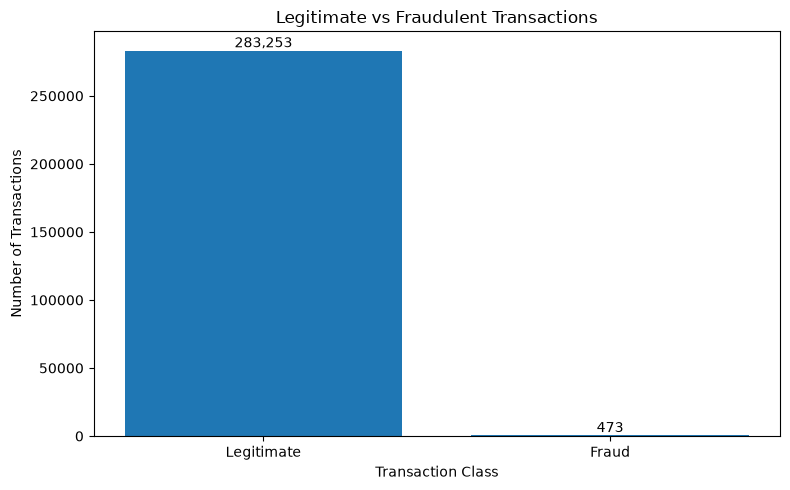

In [10]:
# EDA

# Calculate class counts and fraud prevalence

class_counts = df_clean[TARGET_COLUMN].value_counts().sort_index()

legitimate_count = int(class_counts.get(0, 0))
fraud_count = int(class_counts.get(1, 0))
total_transactions = len(df_clean)

fraud_percentage = (
    fraud_count / total_transactions * 100
)

legitimate_percentage = (
    legitimate_count / total_transactions * 100
)

class_summary = pd.DataFrame({
    "Class": ["Legitimate", "Fraud"],
    "Count": [legitimate_count, fraud_count],
    "Percentage": [
        legitimate_percentage,
        fraud_percentage
    ]
})

display(class_summary)

print(f"Total transactions: {total_transactions:,}")
print(f"Legitimate transactions: {legitimate_count:,}")
print(f"Fraudulent transactions: {fraud_count:,}")
print(f"Fraud prevalence: {fraud_percentage:.6f}%")

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_summary["Class"],
    class_summary["Count"]
)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

for bar, count in zip(bars, class_summary["Count"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    PLOT_DIR / "01_class_distribution.png",
    dpi=150
)
plt.show()


Amount statistics:


,count,mean,median,std,min,max
Class,,,,,,
0,283253,88.413575,22.00,250.379023,0.0,25691.16
1,473,123.871860,9.82,260.211041,0.0,2125.87


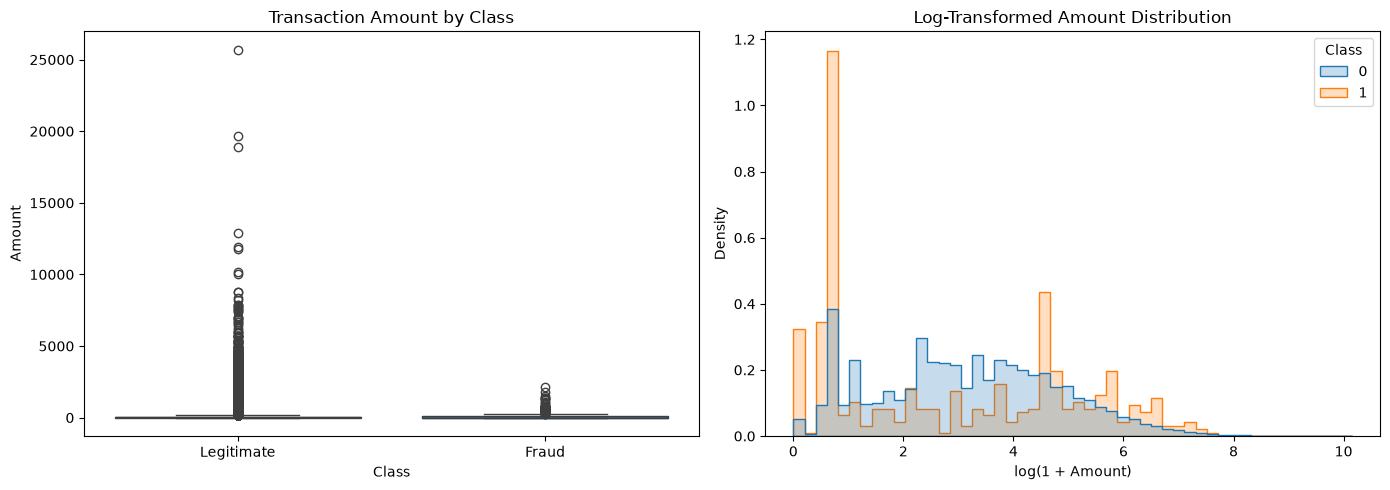

In [11]:
# plot transaction amounts

if "Amount" in df_clean.columns:

    print("Amount statistics:")
    display(
        df_clean.groupby(TARGET_COLUMN)["Amount"]
        .agg([
            "count",
            "mean",
            "median",
            "std",
            "min",
            "max"
        ])
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.boxplot(
        data=df_clean,
        x=TARGET_COLUMN,
        y="Amount",
        ax=axes[0]
    )
    axes[0].set_title("Transaction Amount by Class")
    axes[0].set_xticks([0, 1])
    axes[0].set_xticklabels(["Legitimate", "Fraud"])

    # Log transform only for visualization.
    # Model input remains the original Amount feature.
    amount_plot = df_clean[["Amount", TARGET_COLUMN]].copy()
    amount_plot["LogAmount"] = np.log1p(
        amount_plot["Amount"].clip(lower=0)
    )

    sns.histplot(
        data=amount_plot,
        x="LogAmount",
        hue=TARGET_COLUMN,
        bins=50,
        element="step",
        stat="density",
        common_norm=False,
        ax=axes[1]
    )

    axes[1].set_title("Log-Transformed Amount Distribution")
    axes[1].set_xlabel("log(1 + Amount)")

    plt.tight_layout()
    plt.savefig(
        PLOT_DIR / "02_amount_analysis.png",
        dpi=150
    )
    plt.show()

else:
    print("No Amount column found; skipping amount analysis.")

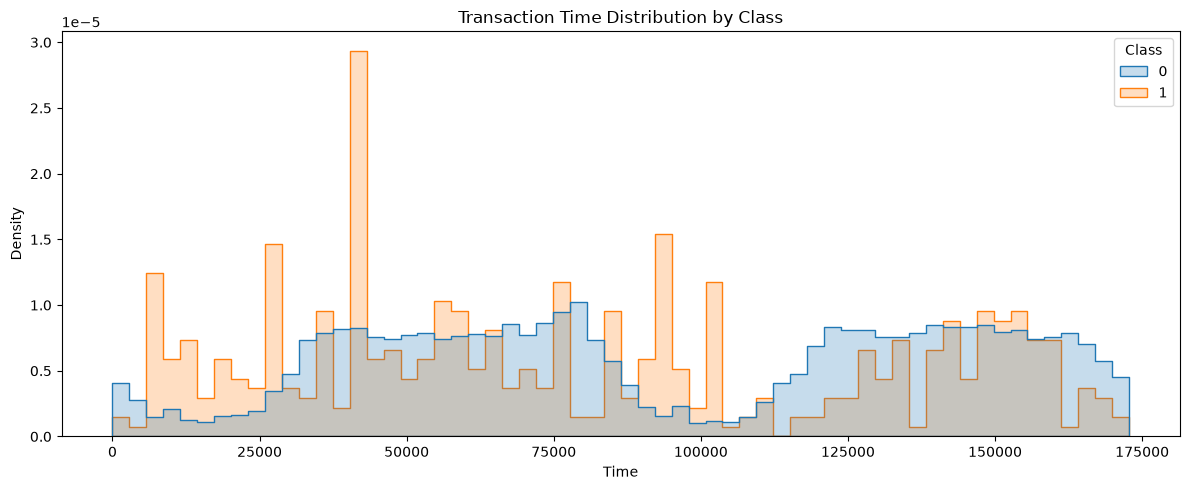

Time statistics:


,mean,median,std,min,max
Class,,,,,
0,94835.058093,84711.0,47475.550607,0.0,172792.0
1,80450.513742,73408.0,48636.179973,406.0,170348.0


In [12]:
# Analyze transaction time

if "Time" in df_clean.columns:

    plt.figure(figsize=(12, 5))

    sns.histplot(
        data=df_clean,
        x="Time",
        hue=TARGET_COLUMN,
        bins=60,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title("Transaction Time Distribution by Class")
    plt.xlabel("Time")
    plt.ylabel("Density")
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / "03_time_distribution.png",
        dpi=150
    )
    plt.show()

    print("Time statistics:")
    display(
        df_clean.groupby(TARGET_COLUMN)["Time"]
        .agg(["mean", "median", "std", "min", "max"])
    )

else:
    print("No Time column found; skipping time analysis.")


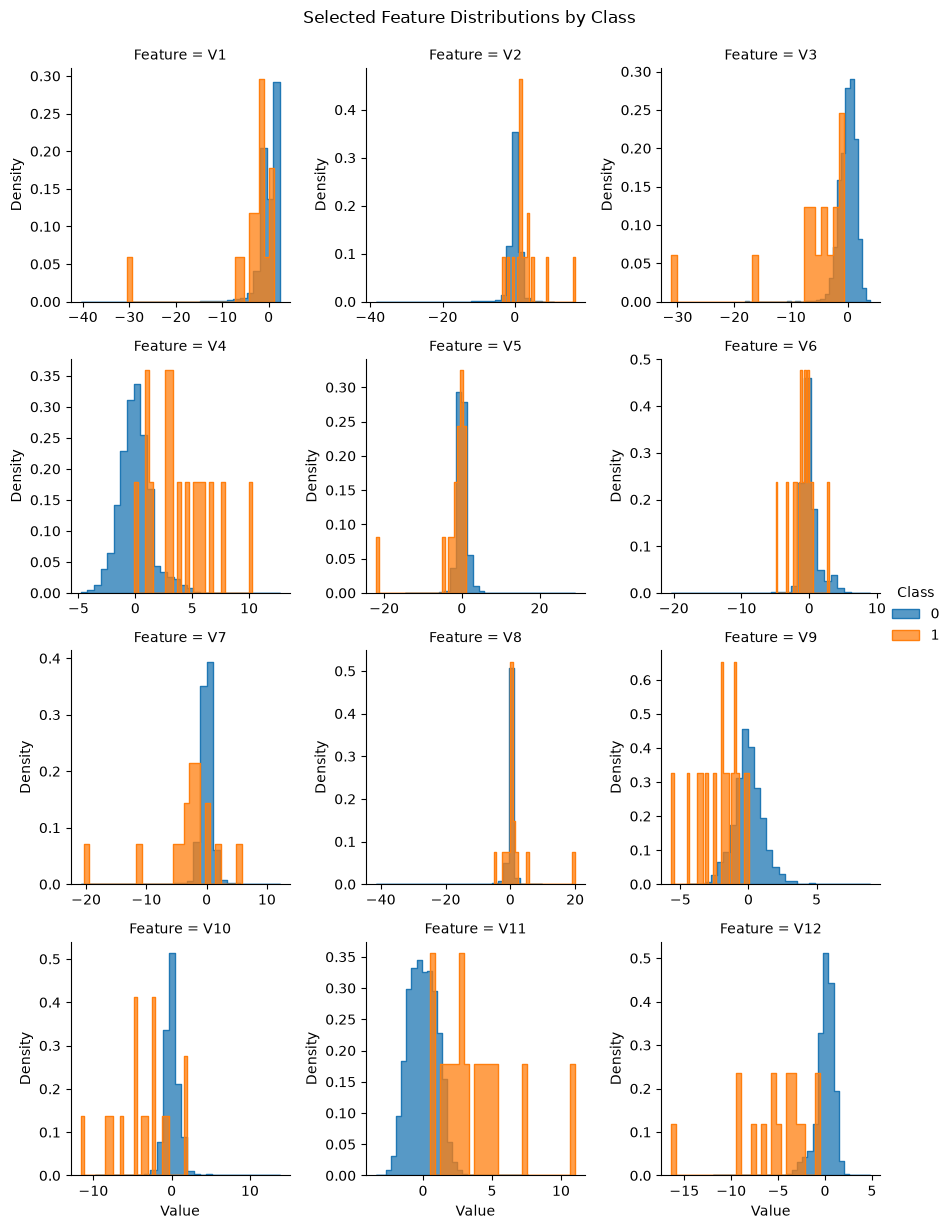

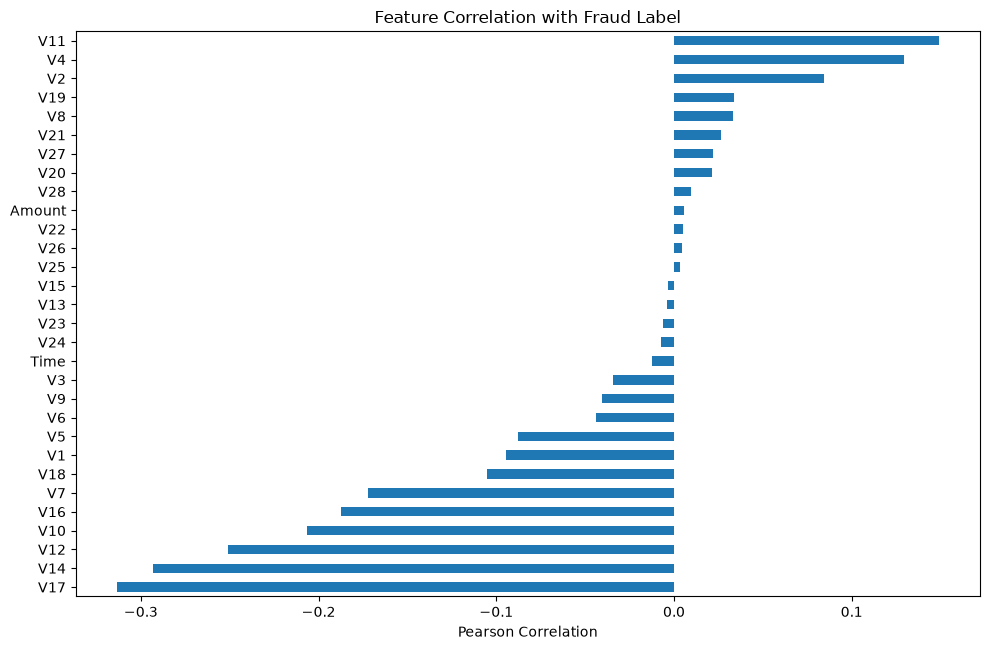

Strongest positive correlations:


V11       0.149068
V4        0.129326
V2        0.084625
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
V28       0.009682
Amount    0.005777
Name: Class, dtype: float64

Strongest negative correlations:


V17   -0.313498
V14   -0.293375
V12   -0.250713
V10   -0.206617
V16   -0.187186
V7    -0.172350
V18   -0.105340
V1    -0.094487
V5    -0.087814
V6    -0.043916
Name: Class, dtype: float64

In [13]:
# Feature distribution and correlation

feature_columns_eda = [
    c for c in df_clean.columns
    if c != TARGET_COLUMN
]

# Sample rows for readable visualizations.
eda_sample = df_clean.sample(
    n=min(10000, len(df_clean)),
    random_state=RANDOM_STATE
)

# Plot up to 12 features, excluding Time and Amount if present.
candidate_features = [
    c for c in feature_columns_eda
    if c not in ["Time", "Amount"]
][:12]

if candidate_features:
    eda_sample_melted = eda_sample[
        candidate_features + [TARGET_COLUMN]
    ].melt(
        id_vars=TARGET_COLUMN,
        var_name="Feature",
        value_name="Value"
    )

    grid = sns.FacetGrid(
        eda_sample_melted,
        col="Feature",
        col_wrap=3,
        hue=TARGET_COLUMN,
        sharex=False,
        sharey=False,
        height=3
    )

    grid.map(
        sns.histplot,
        "Value",
        bins=30,
        element="step",
        stat="density",
        common_norm=False
    )

    grid.add_legend()
    grid.fig.suptitle(
        "Selected Feature Distributions by Class",
        y=1.02
    )

    plt.savefig(
        PLOT_DIR / "04_feature_distributions.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

correlations = (
    df_clean[feature_columns_eda + [TARGET_COLUMN]]
    .corr(numeric_only=True)[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
    .sort_values()
)

plt.figure(figsize=(10, max(6, len(correlations) * 0.22)))
correlations.plot(kind="barh")
plt.title("Feature Correlation with Fraud Label")
plt.xlabel("Pearson Correlation")
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "05_feature_target_correlations.png",
    dpi=150
)
plt.show()

print("Strongest positive correlations:")
display(correlations.tail(10).sort_values(ascending=False))

print("Strongest negative correlations:")
display(correlations.head(10))

In [14]:
# inspecting class-wise feature statistics

classwise_statistics = df_clean.groupby(TARGET_COLUMN)[
    feature_columns_eda
].agg(["mean", "median", "std"])

display(classwise_statistics)

classwise_statistics.to_csv(
    REPORT_DIR / "classwise_feature_statistics.csv"
)

print("Saved class-wise statistics.")


Time                               V1                      \
               mean   median           std      mean    median       std   
Class                                                                      
0      94835.058093  84711.0  47475.550607  0.013455  0.022459  1.922162   
1      80450.513742  73408.0  48636.179973 -4.498280 -2.271755  6.593145   

             V2                            V3  ...       V26       V27  \
           mean    median       std      mean  ...       std      mean   
Class                                          ...                       
0     -0.009821  0.062558  1.633506  0.027906  ...  0.482080  0.001409   
1      3.405965  2.617105  4.122500 -6.729599  ...  0.463016  0.213774   

                                V28                          Amount         \
         median       std      mean    median       std        mean median   
Class                                                                        
0      0.001368  0.392700  0.000418  0.011238  0.327563   88.413575  22.00   
1      0.394682  1.245779  0.078270  0.145895  0.533100  123.871860   9.82   

                   
              std  
Class              
0      250.379023  
1      260.211041  

[2 rows x 90 columns]

Saved class-wise statistics.


In [15]:
# Train, validation and test split

# Stratified data splitting

X = df_clean.drop(columns=[TARGET_COLUMN]).copy()
y = df_clean[TARGET_COLUMN].copy()

# 70% training, 30% temporary.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# Divide the temporary 30% into 15% validation and 15% test.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# Ensure no records are shared between the splits.
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Legitimate": [
        int((y_train == 0).sum()),
        int((y_val == 0).sum()),
        int((y_test == 0).sum())
    ],
    "Fraud": [
        int((y_train == 1).sum()),
        int((y_val == 1).sum()),
        int((y_test == 1).sum())
    ],
    "Fraud Percentage": [
        100 * y_train.mean(),
        100 * y_val.mean(),
        100 * y_test.mean()
    ]
})

display(split_summary)

split_summary.to_csv(
    REPORT_DIR / "data_split_summary.csv",
    index=False
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


,Split,Rows,Legitimate,Fraud,Fraud Percentage
0,Training,198608,198277,331,0.166660
1,Validation,42559,42488,71,0.166827
2,Test,42559,42488,71,0.166827


Training: (198608, 30)
Validation: (42559, 30)
Test: (42559, 30)


In [16]:
# remove constant features using training data only

constant_features = [
    column
    for column in X_train.columns
    if X_train[column].nunique(dropna=True) <= 1
]

print("Constant features found:", constant_features)

X_train = X_train.drop(columns=constant_features)
X_val = X_val.drop(columns=constant_features)
X_test = X_test.drop(columns=constant_features)

FEATURE_COLUMNS = X_train.columns.tolist()

print("Remaining feature count:", len(FEATURE_COLUMNS))

assert X_train.columns.tolist() == X_val.columns.tolist()
assert X_train.columns.tolist() == X_test.columns.tolist()
assert len(FEATURE_COLUMNS) > 0


Constant features found: []
Remaining feature count: 30


In [17]:
# Preprocessing and class imbalance

# Median imputation

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_val_imputed = imputer.transform(X_val)
X_test_imputed = imputer.transform(X_test)

print("Training shape:", X_train_imputed.shape)
print("Validation shape:", X_val_imputed.shape)
print("Test shape:", X_test_imputed.shape)

print("Missing values after training imputation:")
print("Train:", np.isnan(X_train_imputed).sum())
print("Validation:", np.isnan(X_val_imputed).sum())
print("Test:", np.isnan(X_test_imputed).sum())

assert np.isfinite(X_train_imputed).all()
assert np.isfinite(X_val_imputed).all()
assert np.isfinite(X_test_imputed).all()


Training shape: (198608, 30)
Validation shape: (42559, 30)
Test shape: (42559, 30)
Missing values after training imputation:
Train: 0
Validation: 0
Test: 0


In [18]:
# feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_imputed
).astype(np.float32)

X_val_scaled = scaler.transform(
    X_val_imputed
).astype(np.float32)

X_test_scaled = scaler.transform(
    X_test_imputed
).astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.int32)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

print(
    "Training feature means (first 5):",
    X_train_scaled.mean(axis=0)[:5]
)

print(
    "Training feature standard deviations (first 5):",
    X_train_scaled.std(axis=0)[:5]
)

assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_val_scaled).all()
assert np.isfinite(X_test_scaled).all()

Scaled training shape: (198608, 30)
Scaled validation shape: (42559, 30)
Scaled test shape: (42559, 30)
Training feature means (first 5): [ 3.0731470e-10 -1.1524301e-10  7.6828675e-11  2.4969318e-10
 -7.6828675e-11]
Training feature standard deviations (first 5): [1.         1.         0.99999994 1.         0.99999994]


In [19]:
# calculate class weights

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.to_numpy()
)

class_weight_dict = {
    int(class_label): float(weight)
    for class_label, weight in zip(classes, weights)
}

print("Class weights:", class_weight_dict)

class_weight_table = pd.DataFrame({
    "Class": ["Legitimate", "Fraud"],
    "Training Count": [
        int((y_train == 0).sum()),
        int((y_train == 1).sum())
    ],
    "Weight": [
        class_weight_dict[0],
        class_weight_dict[1]
    ]
})

display(class_weight_table)

class_weight_table.to_csv(
    REPORT_DIR / "class_weights.csv",
    index=False
)


Class weights: {0: 0.5008346908617742, 1: 300.012084592145}


,Class,Training Count,Weight
0,Legitimate,198277,0.500835
1,Fraud,331,300.012085


In [20]:
# build deep neural network

def build_fraud_model(input_dim, learning_rate=0.001):

    inputs = tf.keras.Input(
        shape=(input_dim,),
        name="transaction_features"
    )

    x = tf.keras.layers.Dense(
        128,
        use_bias=False,
        name="dense_128"
    )(inputs)

    x = tf.keras.layers.BatchNormalization(
        name="batch_norm_1"
    )(x)

    x = tf.keras.layers.Activation(
        "relu",
        name="relu_1"
    )(x)

    x = tf.keras.layers.Dropout(
        0.30,
        name="dropout_1"
    )(x)

    x = tf.keras.layers.Dense(
        64,
        use_bias=False,
        name="dense_64"
    )(x)

    x = tf.keras.layers.BatchNormalization(
        name="batch_norm_2"
    )(x)

    x = tf.keras.layers.Activation(
        "relu",
        name="relu_2"
    )(x)

    x = tf.keras.layers.Dropout(
        0.25,
        name="dropout_2"
    )(x)

    x = tf.keras.layers.Dense(
        32,
        activation="relu",
        name="dense_32"
    )(x)

    x = tf.keras.layers.Dropout(
        0.15,
        name="dropout_3"
    )(x)

    outputs = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="fraud_probability"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="CreditCardFraudDNN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(
                name="accuracy"
            ),
            tf.keras.metrics.Precision(
                name="precision"
            ),
            tf.keras.metrics.Recall(
                name="recall"
            ),
            tf.keras.metrics.AUC(
                name="roc_auc",
                curve="ROC"
            ),
            tf.keras.metrics.AUC(
                name="pr_auc",
                curve="PR"
            )
        ]
    )

    return model


model = build_fraud_model(
    input_dim=X_train_scaled.shape[1],
    learning_rate=0.001
)

model.summary()


Model: "CreditCardFraudDNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ transaction_features            │ (None, 30)             │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │         3,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fraud_probability (Dense)       │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,913 (58.25 KB)

 Trainable params: 14,529 (56.75 KB)

 Non-trainable params: 384 (1.50 KB)

In [21]:
# Training callbacks

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(DL_MODEL_PATH),
    monitor="val_pr_auc",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

lr_callback = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_pr_auc",
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    lr_callback
]

print("Callbacks configured.")


Callbacks configured.


In [22]:
# training the model

history = model.fit(
    X_train_scaled,
    y_train_np,
    validation_data=(
        X_val_scaled,
        y_val_np
    ),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    REPORT_DIR / "fraud_dl_training_history.csv",
    index_label="epoch"
)

print("\nTraining finished.")
print("Epochs executed:", len(history_df))
print("Best validation PR-AUC:", history_df["val_pr_auc"].max())
print("Saved checkpoint:", DL_MODEL_PATH)


Epoch 1/50
95/97 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7970 - loss: 0.3488 - pr_auc: 0.3615 - precision: 0.0073 - recall: 0.8981 - roc_auc: 0.9267
Epoch 1: val_pr_auc improved from None to 0.72593, saving model to C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\best_fraud_dl_model.keras

Epoch 1: finished saving model to C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\best_fraud_dl_model.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.8002 - loss: 0.3487 - pr_auc: 0.3563 - precision: 0.0074 - recall: 0.8943 - roc_auc: 0.9264 - val_accuracy: 0.9691 - val_loss: 0.2994 - val_pr_auc: 0.7259 - val_precision: 0.0466 - val_recall: 0.9014 - val_roc_auc: 0.9679 - learning_rate: 0.0010
Epoch 2/50
95/97 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9593 - loss: 0.2047 - pr_auc: 0.5347 - precision: 0.0357 - recall: 0.9012 - roc_auc: 0.9666
Epoch 2: val_pr_auc improved from 0.72593 to 0.74494, saving model to C:\Users\gargn\OneDrive\Desk

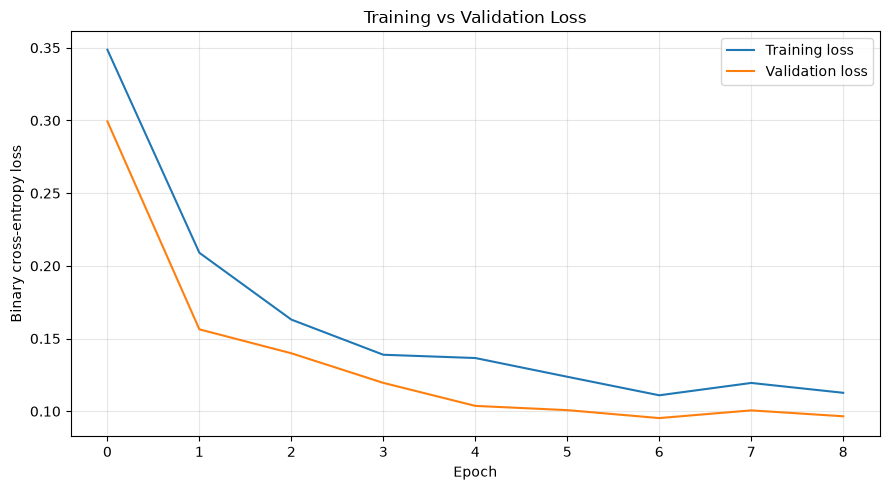

In [23]:
# Plot training and validation loss

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "06_loss_curves.png",
    dpi=150
)

plt.show()


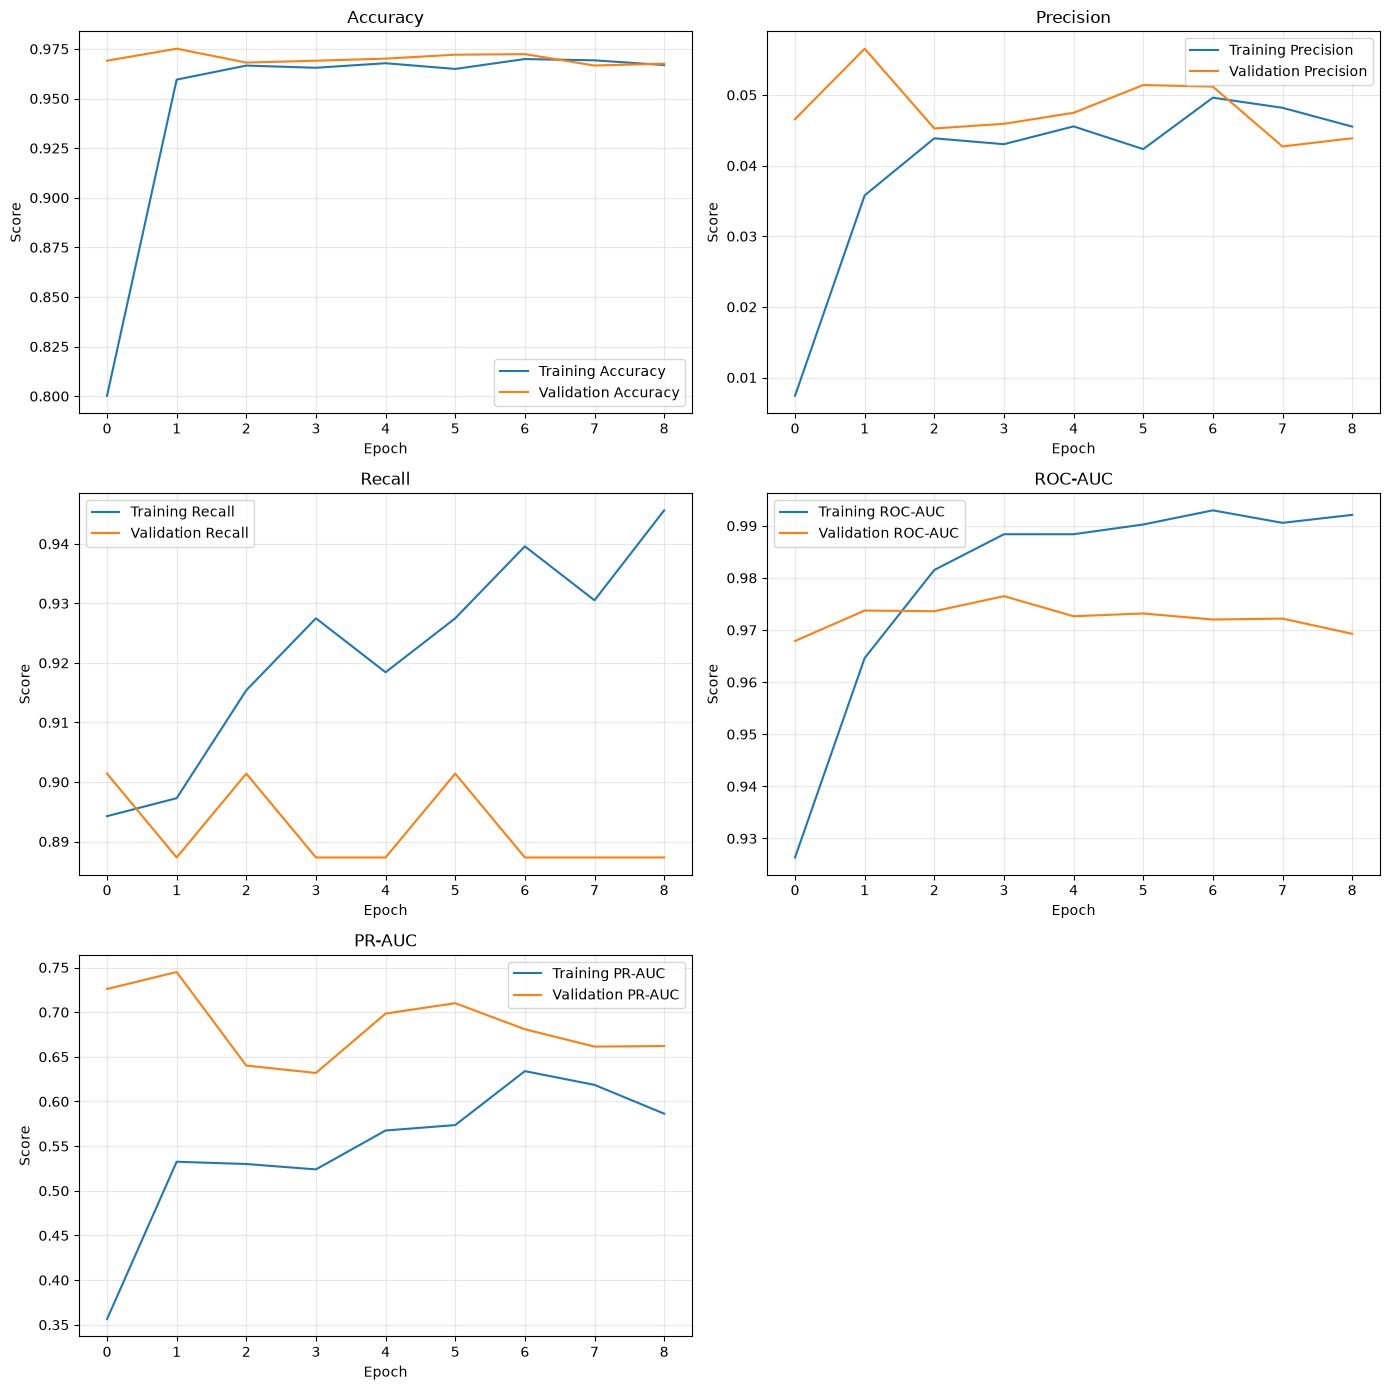

In [24]:
# Training metric curves

metric_pairs = [
    ("accuracy", "val_accuracy", "Accuracy"),
    ("precision", "val_precision", "Precision"),
    ("recall", "val_recall", "Recall"),
    ("roc_auc", "val_roc_auc", "ROC-AUC"),
    ("pr_auc", "val_pr_auc", "PR-AUC")
]

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 14)
)

axes = axes.flatten()

for i, (train_key, val_key, title) in enumerate(metric_pairs):

    axes[i].plot(
        history.history[train_key],
        label=f"Training {title}"
    )

    axes[i].plot(
        history.history[val_key],
        label=f"Validation {title}"
    )

    axes[i].set_title(title)
    axes[i].set_xlabel("Epoch")
    axes[i].set_ylabel("Score")
    axes[i].legend()
    axes[i].grid(alpha=0.3)

axes[-1].axis("off")

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "07_training_metrics.png",
    dpi=150
)

plt.show()


In [25]:
# Restore best checkpoint

if not DL_MODEL_PATH.is_file():
    raise FileNotFoundError(
        "Best checkpoint was not saved. Check the training output."
    )

model = tf.keras.models.load_model(
    DL_MODEL_PATH
)

print("Best checkpoint loaded successfully.")
print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Best checkpoint loaded successfully.
Model name: CreditCardFraudDNN
Input shape: (None, 30)
Output shape: (None, 1)


In [26]:
# Validation predictions

val_probabilities = model.predict(
    X_val_scaled,
    batch_size=BATCH_SIZE,
    verbose=0
).ravel()

print("Validation predictions:", val_probabilities.shape)
print("Minimum probability:", val_probabilities.min())
print("Maximum probability:", val_probabilities.max())

assert np.isfinite(val_probabilities).all()

validation_ap = average_precision_score(
    y_val_np.astype(int),
    val_probabilities
)

validation_roc_auc = roc_auc_score(
    y_val_np.astype(int),
    val_probabilities
)

print(f"Validation average precision: {validation_ap:.6f}")
print(f"Validation ROC-AUC: {validation_roc_auc:.6f}")


Validation predictions: (42559,)
Minimum probability: 1.6526945e-05
Maximum probability: 1.0
Validation average precision: 0.692436
Validation ROC-AUC: 0.973619


Selected threshold: 0.9921321272850037
Validation precision: 0.9032258064516129
Validation recall: 0.7887323943661971
Validation F1-score: 0.842105263157397


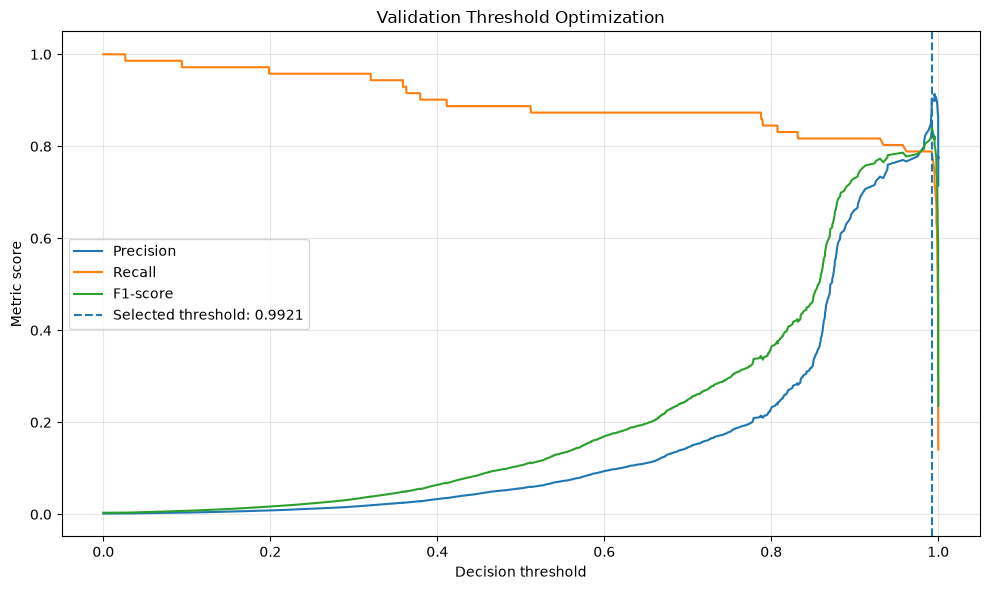

In [27]:
# Threshold tuning

precision_vals, recall_vals, thresholds = precision_recall_curve(
    y_val_np.astype(int),
    val_probabilities
)

# The last precision/recall point has no corresponding threshold.
precision_for_thresholds = precision_vals[:-1]
recall_for_thresholds = recall_vals[:-1]

f1_values = (
    2 * precision_for_thresholds * recall_for_thresholds
    / (
        precision_for_thresholds
        + recall_for_thresholds
        + 1e-12
    )
)

if len(thresholds) == 0:
    raise ValueError(
        "No candidate thresholds were returned."
    )

best_idx = int(np.nanargmax(f1_values))

best_threshold = float(thresholds[best_idx])

best_validation_precision = float(
    precision_for_thresholds[best_idx]
)

best_validation_recall = float(
    recall_for_thresholds[best_idx]
)

best_validation_f1 = float(
    f1_values[best_idx]
)

print("Selected threshold:", best_threshold)
print("Validation precision:", best_validation_precision)
print("Validation recall:", best_validation_recall)
print("Validation F1-score:", best_validation_f1)

threshold_results = pd.DataFrame({
    "Threshold": thresholds,
    "Precision": precision_for_thresholds,
    "Recall": recall_for_thresholds,
    "F1-score": f1_values
})

threshold_results.to_csv(
    REPORT_DIR / "validation_threshold_results.csv",
    index=False
)

plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    precision_for_thresholds,
    label="Precision"
)

plt.plot(
    thresholds,
    recall_for_thresholds,
    label="Recall"
)

plt.plot(
    thresholds,
    f1_values,
    label="F1-score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold: {best_threshold:.4f}"
)

plt.xlabel("Decision threshold")
plt.ylabel("Metric score")
plt.title("Validation Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "08_threshold_tuning.png",
    dpi=150
)

plt.show()


In [28]:
# saving threshold

threshold_info = {
    "threshold": best_threshold,
    "selection_method": "maximum validation F1-score",
    "validation_precision": best_validation_precision,
    "validation_recall": best_validation_recall,
    "validation_f1": best_validation_f1,
    "validation_average_precision": float(validation_ap),
    "validation_roc_auc": float(validation_roc_auc)
}

with open(
    THRESHOLD_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(threshold_info, file, indent=4)

print("Threshold saved to:", THRESHOLD_PATH)

Threshold saved to: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\fraud_dl_threshold.json


In [29]:
# evaluating model on test set

test_probabilities = model.predict(
    X_test_scaled,
    batch_size=BATCH_SIZE,
    verbose=0
).ravel()

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)


def evaluate_binary_model(
    y_true,
    predictions,
    probabilities,
    model_name
):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_true, predictions
        ),
        "Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_true, probabilities
        )
    }


dl_metrics = evaluate_binary_model(
    y_test_np,
    test_predictions,
    test_probabilities,
    "Deep Learning"
)

dl_metrics_df = pd.DataFrame([dl_metrics])

display(dl_metrics_df.round(6))

dl_metrics_df.to_csv(
    REPORT_DIR / "dl_test_metrics.csv",
    index=False
)

print("\nClassification report:")
print(
    classification_report(
        y_test_np,
        test_predictions,
        labels=[0, 1],
        target_names=[
            "Legitimate",
            "Fraud"
        ],
        zero_division=0
    )
)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Deep Learning,0.999342,0.811594,0.788732,0.8,0.959646,0.668412



Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42488
       Fraud       0.81      0.79      0.80        71

    accuracy                           1.00     42559
   macro avg       0.91      0.89      0.90     42559
weighted avg       1.00      1.00      1.00     42559



True negatives: 42475
False positives: 13
False negatives: 15
True positives: 56


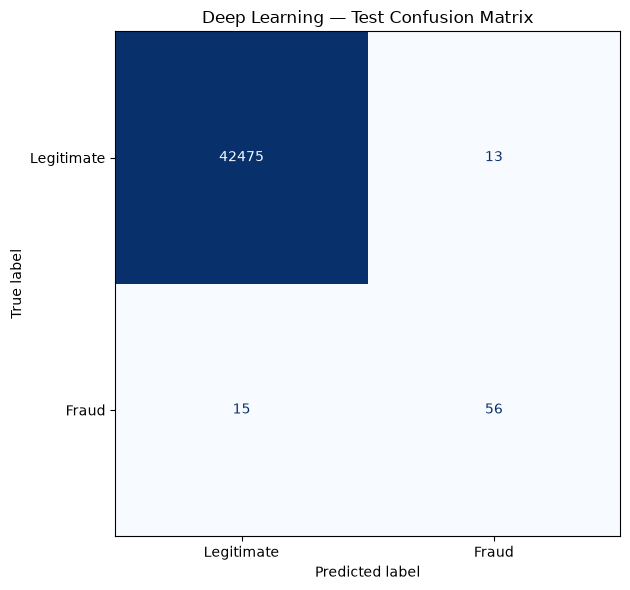

In [31]:
# plot confusion matrix

cm = confusion_matrix(
    y_test_np,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Legitimate",
        "Fraud"
    ]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Deep Learning — Test Confusion Matrix")

plt.tight_layout()
plt.savefig(
    PLOT_DIR / "09_dl_confusion_matrix.png",
    dpi=150
)
plt.show()


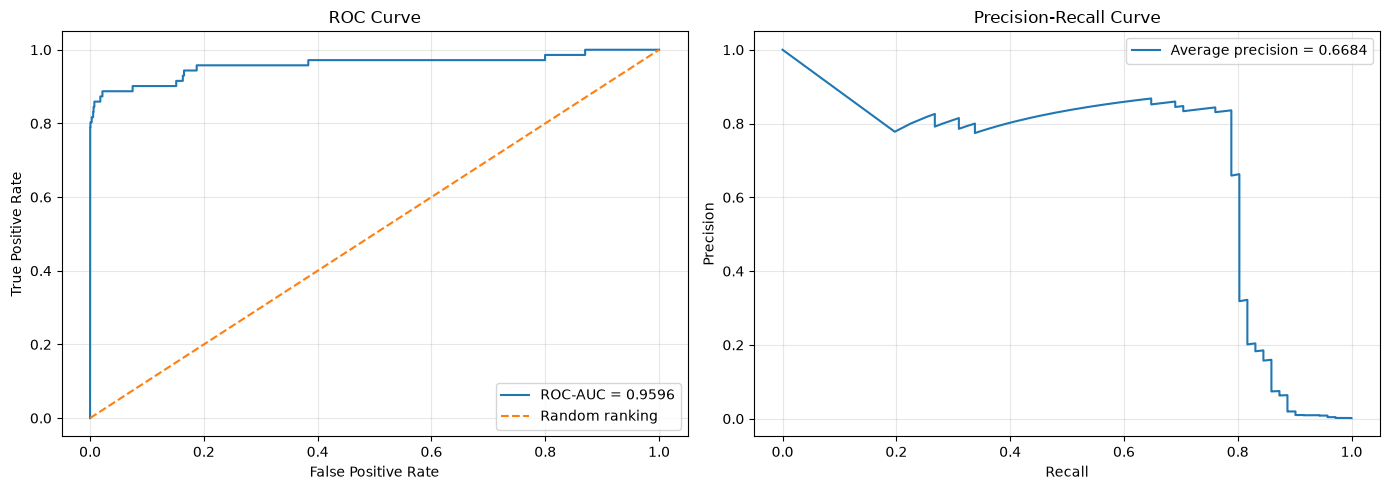

In [32]:
# plot ROC and precision-recall curves

fpr, tpr, roc_thresholds = roc_curve(
    y_test_np,
    test_probabilities
)

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_test_np,
    test_probabilities
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc_score(y_test_np, test_probabilities):.4f}"
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    pr_recall,
    pr_precision,
    label=f"Average precision = {average_precision_score(y_test_np, test_probabilities):.4f}"
)

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    PLOT_DIR / "10_dl_roc_pr_curves.png",
    dpi=150
)
plt.show()


In [33]:
# saving deployment artifacts

# Save the best Keras model.
model.save(DL_MODEL_PATH)

# Save all preprocessing objects and the exact feature order.
preprocessor_bundle = {
    "imputer": imputer,
    "scaler": scaler,
    "feature_columns": FEATURE_COLUMNS,
    "target_column": TARGET_COLUMN,
    "constant_features_removed": constant_features,
    "imputation_strategy": "median",
    "scaling_strategy": "StandardScaler"
}

joblib.dump(
    preprocessor_bundle,
    PREPROCESSOR_PATH
)

metadata = {
    "model_name": "Credit Card Fraud Detection DNN",
    "model_type": "TensorFlow/Keras",
    "target_column": TARGET_COLUMN,
    "class_mapping": {
        "0": "Legitimate transaction",
        "1": "Fraudulent transaction"
    },
    "feature_columns": FEATURE_COLUMNS,
    "input_dimension": len(FEATURE_COLUMNS),
    "constant_features_removed": constant_features,
    "random_state": RANDOM_STATE,
    "train_fraction": TRAIN_SIZE,
    "validation_fraction": VALIDATION_SIZE,
    "test_fraction": TEST_SIZE,
    "imbalance_strategy": "class_weight",
    "threshold_selection": "maximum validation F1-score",
    "batch_size": BATCH_SIZE,
    "maximum_epochs": MAX_EPOCHS,
    "tensorflow_version": tf.__version__,
    "scikit_learn_version": sklearn.__version__,
    "model_filename": DL_MODEL_PATH.name,
    "preprocessor_filename": PREPROCESSOR_PATH.name,
    "threshold_filename": THRESHOLD_PATH.name
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=4)

print("Saved files:")

for path in [
    DL_MODEL_PATH,
    PREPROCESSOR_PATH,
    METADATA_PATH,
    THRESHOLD_PATH
]:
    print(
        path,
        "| Exists:", path.exists(),
        "| Size:",
        f"{path.stat().st_size:,} bytes"
        if path.exists() else "Missing"
    )


Saved files:
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\best_fraud_dl_model.keras | Exists: True | Size: 232,544 bytes
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\fraud_preprocessor.joblib | Exists: True | Size: 2,553 bytes
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\fraud_dl_metadata.json | Exists: True | Size: 1,321 bytes
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\fraud_dl_threshold.json | Exists: True | Size: 337 bytes


In [34]:
# reload and verify saved model

reloaded_model = tf.keras.models.load_model(
    DL_MODEL_PATH
)

reloaded_preprocessor = joblib.load(
    PREPROCESSOR_PATH
)

with open(
    THRESHOLD_PATH,
    "r",
    encoding="utf-8"
) as file:
    reloaded_threshold_info = json.load(file)

reloaded_threshold = float(
    reloaded_threshold_info["threshold"]
)

# Use the saved feature order and saved preprocessing.
X_test_reloaded = X_test[
    reloaded_preprocessor["feature_columns"]
].copy()

X_test_reloaded_imputed = (
    reloaded_preprocessor["imputer"]
    .transform(X_test_reloaded)
)

X_test_reloaded_scaled = (
    reloaded_preprocessor["scaler"]
    .transform(X_test_reloaded_imputed)
    .astype(np.float32)
)

scores_before_save = model.predict(
    X_test_scaled,
    batch_size=BATCH_SIZE,
    verbose=0
).ravel()

scores_after_reload = reloaded_model.predict(
    X_test_reloaded_scaled,
    batch_size=BATCH_SIZE,
    verbose=0
).ravel()

maximum_difference = float(
    np.max(
        np.abs(
            scores_before_save - scores_after_reload
        )
    )
)

print("Maximum prediction difference:", maximum_difference)
print("Reloaded threshold:", reloaded_threshold)

assert np.allclose(
    scores_before_save,
    scores_after_reload,
    atol=1e-5
)

assert np.isclose(
    reloaded_threshold,
    best_threshold
)

print("Saved model verification passed.")


Maximum prediction difference: 0.0
Reloaded threshold: 0.9921321272850037
Saved model verification passed.


In [35]:
# Compare ML and DL

# Locate and inspect the existing ML artifact

ML_MODEL_CANDIDATES = [
    PROJECT_DIR / "models" / "best_fraud_model.joblib",
    PROJECT_DIR.parent / "ML Model" / "models" / "best_fraud_model.joblib"
]

ml_model_path = next(
    (
        path for path in ML_MODEL_CANDIDATES
        if path.is_file()
    ),
    None
)

if ml_model_path is None:
    print("ML model artifact not found.")
    print("Expected locations:")
    for path in ML_MODEL_CANDIDATES:
        print("-", path)
    print(
        "Save your existing ML model before running the "
        "comparison cells."
    )
else:
    ml_bundle = joblib.load(ml_model_path)

    print("ML artifact:", ml_model_path)
    print("Artifact type:", type(ml_bundle))

    if isinstance(ml_bundle, dict):
        print("Available keys:", list(ml_bundle.keys()))
    else:
        print("Loaded a standalone estimator.")


ML artifact: C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\ML Model\models\best_fraud_model.joblib
Artifact type: <class 'dict'>
Available keys: ['model', 'model_name', 'threshold', 'feature_names', 'target_name', 'class_mapping']


In [36]:
# generate ML test predictions

ml_metrics_df = None

if ml_model_path is not None:

    if isinstance(ml_bundle, dict):

        ml_estimator = next(
            (
                ml_bundle[key]
                for key in [
                    "pipeline",
                    "model",
                    "best_model",
                    "estimator"
                ]
                if key in ml_bundle
            ),
            None
        )

        if ml_estimator is None:
            raise KeyError(
                "No fitted estimator found. "
                f"Bundle keys: {list(ml_bundle.keys())}"
            )

        ml_threshold = float(
            ml_bundle.get(
                "threshold",
                ml_bundle.get("best_threshold", 0.5)
            )
        )

        ml_features = ml_bundle.get(
            "feature_columns",
            ml_bundle.get(
                "feature_names",
                FEATURE_COLUMNS
            )
        )

    else:
        ml_estimator = ml_bundle
        ml_threshold = 0.5
        ml_features = FEATURE_COLUMNS

    ml_features = list(ml_features)

    missing_features = [
        column for column in ml_features
        if column not in X_test.columns
    ]

    if missing_features:
        raise ValueError(
            "ML model expects missing test features: "
            f"{missing_features}"
        )

    X_test_ml = X_test[ml_features].copy()

    if not hasattr(ml_estimator, "predict_proba"):
        raise TypeError(
            "This comparison requires an ML estimator with "
            "predict_proba(). If the estimator only supports "
            "decision_function(), calibrate it on training/validation "
            "data before comparing probability-based thresholds."
        )

    ml_probabilities = ml_estimator.predict_proba(
        X_test_ml
    )[:, 1]

    ml_predictions = (
        ml_probabilities >= ml_threshold
    ).astype(int)

    ml_metrics = evaluate_binary_model(
        y_test_np,
        ml_predictions,
        ml_probabilities,
        "Machine Learning"
    )

    ml_metrics_df = pd.DataFrame([ml_metrics])

    display(ml_metrics_df.round(6))

    print("ML threshold:", ml_threshold)
    print("DL threshold:", best_threshold)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Machine Learning,0.999413,0.838235,0.802817,0.820144,0.960652,0.805542


ML threshold: 0.2896954271091346
DL threshold: 0.9921321272850037


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Model,,,,,,
Machine Learning,0.999413,0.838235,0.802817,0.820144,0.960652,0.805542
Deep Learning,0.999342,0.811594,0.788732,0.800000,0.959646,0.668412


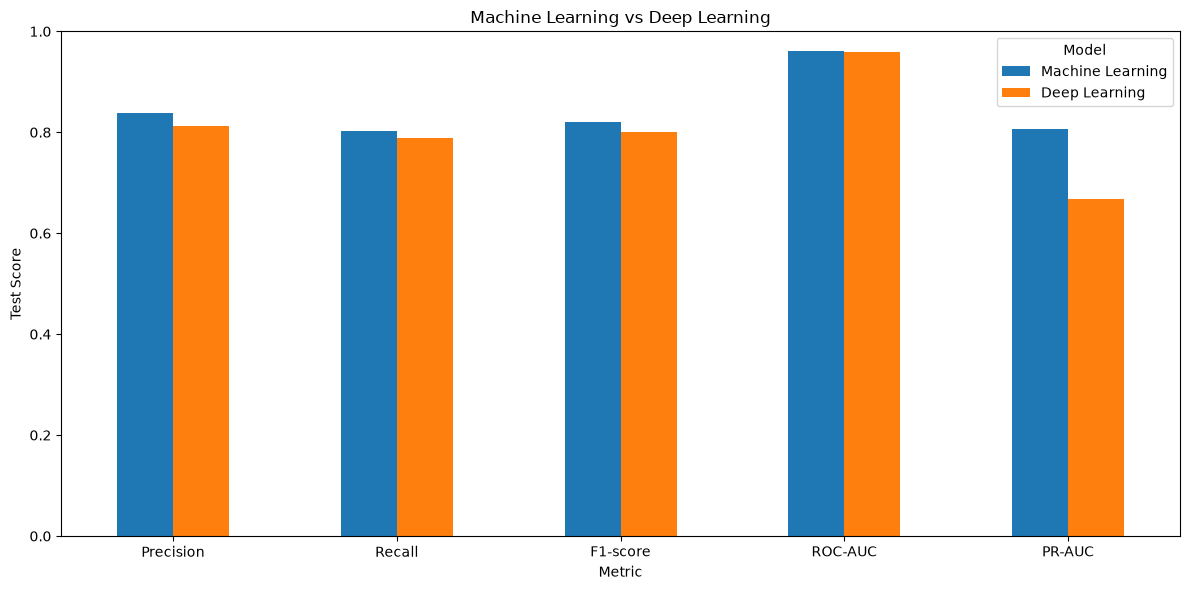

In [37]:
# Build ML versus DL comparison table

dl_metrics_df = pd.DataFrame([dl_metrics])

if ml_metrics_df is not None:

    comparison_df = pd.concat(
        [ml_metrics_df, dl_metrics_df],
        ignore_index=True
    )

    comparison_df.to_csv(
        REPORT_DIR / "ml_dl_test_comparison.csv",
        index=False
    )

    display(
        comparison_df
        .set_index("Model")
        .round(6)
    )

    metrics_to_plot = [
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC"
    ]

    ax = (
        comparison_df
        .set_index("Model")[metrics_to_plot]
        .T
        .plot(
            kind="bar",
            figsize=(12, 6)
        )
    )

    ax.set_title("Machine Learning vs Deep Learning")
    ax.set_ylabel("Test Score")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Metric")
    plt.xticks(rotation=0)
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / "11_ml_dl_comparison.png",
        dpi=150
    )

    plt.show()

else:
    print(
        "DL metrics are ready, but the ML comparison "
        "was skipped because the ML artifact was unavailable."
    )

In [38]:
# Final experiment summary

final_summary = {
    "project": "Credit Card Fraud Detection",
    "model": "Deep Learning DNN",
    "target": TARGET_COLUMN,
    "random_state": RANDOM_STATE,
    "split": {
        "training_rows": int(len(X_train)),
        "validation_rows": int(len(X_val)),
        "test_rows": int(len(X_test))
    },
    "class_distribution": {
        "training_fraud": int(y_train.sum()),
        "validation_fraud": int(y_val.sum()),
        "test_fraud": int(y_test.sum())
    },
    "selected_threshold": float(best_threshold),
    "test_metrics": {
        key: float(value)
        for key, value in dl_metrics.items()
        if key != "Model"
    },
    "confusion_matrix": {
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    },
    "artifacts": {
        "model": DL_MODEL_PATH.name,
        "preprocessor": PREPROCESSOR_PATH.name,
        "metadata": METADATA_PATH.name,
        "threshold": THRESHOLD_PATH.name
    }
}

with open(
    REPORT_DIR / "dl_final_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_summary, file, indent=4)

print("Experiment summary saved.")

print("\nFinal model artifacts:")
for path in [
    DL_MODEL_PATH,
    PREPROCESSOR_PATH,
    METADATA_PATH,
    THRESHOLD_PATH
]:
    print(path, "->", path.exists())

print("\nReport files:")
for path in sorted(REPORT_DIR.glob("*")):
    print(path.name)

print("\nPlot files:")
for path in sorted(PLOT_DIR.glob("*")):
    print(path.name)


Experiment summary saved.

Final model artifacts:
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\best_fraud_dl_model.keras -> True
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\fraud_preprocessor.joblib -> True
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\fraud_dl_metadata.json -> True
C:\Users\gargn\OneDrive\Desktop\AI & ML\Capstone 2\DL Model\models\fraud_dl_threshold.json -> True

Report files:
class_weights.csv
classwise_feature_statistics.csv
data_split_summary.csv
dl_final_summary.json
dl_test_metrics.csv
fraud_dl_training_history.csv
ml_dl_test_comparison.csv
validation_threshold_results.csv

Plot files:
01_class_distribution.png
02_amount_analysis.png
03_time_distribution.png
04_feature_distributions.png
05_feature_target_correlations.png
06_loss_curves.png
07_training_metrics.png
08_threshold_tuning.png
09_dl_confusion_matrix.png
10_dl_roc_pr_curves.png
11_ml_dl_comparison.png
